In [1]:
import pandas as pd
import numpy as np

In [2]:
from pathlib import Path

data_path = Path("dataset/listings.csv")

if not data_path.exists():
    data_path = Path("../dataset/listings.csv")

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 25338
Number of Columns: 19


In [4]:
df.head()

,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,23986,""" Characteristic Milanese flat""",95941,1462509479093385637,Jeremy,NaN,NAVIGLI,45.448060,9.173730,Entire home/apt,203.0,31.0,26,2024-04-20,0.15,1,362,0,NaN
1,40470,Giacinto Cosy & clean flat near MM1,174203,1462511755749357359,Giacinto,NaN,VIALE MONZA,45.520230,9.227470,Entire home/apt,137.0,3.0,44,2025-07-31,0.23,2,323,0,IT015146C2YDCLSU8G
2,46536,Nico & Cinzia's Pink Suite!,138683,1462510639865556122,Nico&Cinzia,NaN,VIALE MONZA,45.522760,9.224780,Entire home/apt,NaN,3.0,40,2026-01-04,0.22,1,0,1,IT015209C2BBKGCMT7
3,84741,Nice room with private bathroom,443989,1462511875583371743,Franci,NaN,PARCO FORLANINI - ORTICA,45.469994,9.244106,Private room,NaN,31.0,701,2026-08-30,3.75,3,235,9,"I applied for a CIN, but haven’t received it yet"
4,88130,Great comfortable & quite APT. x 4 people!,481475,1462519456127538560,Cinzia,NaN,VILLAPIZZONE,45.497640,9.145330,Entire home/apt,102.0,31.0,7,2022-10-01,0.04,1,363,0,NaN


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25338 entries, 0 to 25337
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              25338 non-null  int64  
 1   name                            25338 non-null  str    
 2   host_id                         25338 non-null  int64  
 3   host_profile_id                 25338 non-null  int64  
 4   host_name                       25338 non-null  str    
 5   neighbourhood_group             0 non-null      float64
 6   neighbourhood                   25338 non-null  str    
 7   latitude                        25338 non-null  float64
 8   longitude                       25338 non-null  float64
 9   room_type                       25338 non-null  str    
 10  price                           21654 non-null  float64
 11  minimum_nights                  25186 non-null  float64
 12  number_of_reviews               25338 non-n

In [6]:
df.isnull().sum()

id                                    0
name                                  0
host_id                               0
host_profile_id                       0
host_name                             0
neighbourhood_group               25338
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                              3684
minimum_nights                      152
number_of_reviews                     0
last_review                        3664
reviews_per_month                  3664
calculated_host_listings_count        0
availability_365                      0
number_of_reviews_ltm                 0
license                            3851
dtype: int64

In [7]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [8]:
df_clean = df.copy()

print("Original dataset:", df.shape)
print("Working dataset:", df_clean.shape)

Original dataset: (25338, 19)
Working dataset: (25338, 19)


In [9]:
df_clean = df_clean.drop(columns=["neighbourhood_group"])

print("Columns after removing empty column:", df_clean.shape[1])

Columns after removing empty column: 18


In [10]:
df_clean = df_clean.dropna(subset=["price"])

print("Rows after removing missing prices:", len(df_clean))

Rows after removing missing prices: 21654


In [11]:
df_clean["price"].describe()

count    21654.000000
mean       228.890551
std        824.133751
min         14.000000
25%        120.000000
50%        164.000000
75%        232.000000
max      88100.000000
Name: price, dtype: float64

In [12]:
print("Zero prices:", (df_clean["price"] == 0).sum())
print("Negative prices:", (df_clean["price"] < 0).sum())

Zero prices: 0
Negative prices: 0


In [13]:
df_clean = df_clean[df_clean["price"] > 0].copy()

print("Rows after removing invalid prices:", len(df_clean))

Rows after removing invalid prices: 21654


In [14]:
Q1 = df_clean["price"].quantile(0.25)
Q3 = df_clean["price"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 120.0
Q3: 232.0
IQR: 112.0
Lower limit: -48.0
Upper limit: 400.0


In [15]:
outliers = df_clean[
    (df_clean["price"] < lower_limit) |
    (df_clean["price"] > upper_limit)
]

print("Number of price outliers:", len(outliers))

Number of price outliers: 1568


In [16]:
print("Missing minimum nights:",
      df_clean["minimum_nights"].isnull().sum())

print("Zero minimum nights:",
      (df_clean["minimum_nights"] == 0).sum())

print("Negative minimum nights:",
      (df_clean["minimum_nights"] < 0).sum())

Missing minimum nights: 135
Zero minimum nights: 0
Negative minimum nights: 0


In [17]:
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

Original rows: 25338
Cleaned rows: 21654

Missing values after cleaning:
id                                   0
name                                 0
host_id                              0
host_profile_id                      0
host_name                            0
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
price                                0
minimum_nights                     135
number_of_reviews                    0
last_review                       2931
reviews_per_month                 2931
calculated_host_listings_count       0
availability_365                     0
number_of_reviews_ltm                0
license                           2879
dtype: int64


In [19]:
df_analysis = df_clean[
    df_clean["price"] <= upper_limit
].copy()

print("Cleaned dataset:", len(df_clean))
print("Analysis dataset:", len(df_analysis))
print("Removed outliers:", len(df_clean) - len(df_analysis))

Cleaned dataset: 21654
Analysis dataset: 20086
Removed outliers: 1568


In [20]:
print("Statistics BEFORE removing outliers:")
print(df_clean["price"].describe())

print("\nStatistics AFTER removing outliers:")
print(df_analysis["price"].describe())

Statistics BEFORE removing outliers:
count    21654.000000
mean       228.890551
std        824.133751
min         14.000000
25%        120.000000
50%        164.000000
75%        232.000000
max      88100.000000
Name: price, dtype: float64

Statistics AFTER removing outliers:
count    20086.000000
mean       170.498905
std         75.267812
min         14.000000
25%        117.000000
50%        157.000000
75%        211.000000
max        400.000000
Name: price, dtype: float64


In [21]:
print(
    "Listings with zero reviews:",
    (df_clean["number_of_reviews"] == 0).sum()
)

Listings with zero reviews: 2931


In [22]:
df_clean.to_csv(
    "../dataset/cleaned_listings.csv",
    index=False
)

df_analysis.to_csv(
    "../dataset/analysis_listings.csv",
    index=False
)

print("Both datasets saved successfully!")

Both datasets saved successfully!


In [23]:
# Basic information about the dataset

print("Total listings:", len(df_clean))
print("Listings used for price analysis:", len(df_analysis))

print("\nAverage price:", df_analysis["price"].mean())
print("Median price:", df_analysis["price"].median())
print("Minimum price:", df_analysis["price"].min())
print("Maximum price:", df_analysis["price"].max())

print("\nAverage minimum nights:", df_clean["minimum_nights"].mean())
print("Average number of reviews:", df_clean["number_of_reviews"].mean())
print("Average availability:", df_clean["availability_365"].mean())

Total listings: 21654
Listings used for price analysis: 20086

Average price: 170.49890470974807
Median price: 157.0
Minimum price: 14.0
Maximum price: 400.0

Average minimum nights: 5.362888610065523
Average number of reviews: 49.529648101967304
Average availability: 211.15983190172716


In [24]:
room_counts = df_clean["room_type"].value_counts()

print(room_counts)

room_type
Entire home/apt    19133
Private room        2458
Shared room           48
Hotel room            15
Name: count, dtype: int64


In [25]:
room_percentages = df_clean["room_type"].value_counts(normalize=True) * 100

print(room_percentages.round(2))

room_type
Entire home/apt    88.36
Private room       11.35
Shared room         0.22
Hotel room          0.07
Name: proportion, dtype: float64


In [26]:
room_price = df_analysis.groupby("room_type")["price"].agg(
    ["count", "mean", "median", "min", "max"]
)

print(room_price.round(2))


                 count    mean  median    min    max
room_type                                           
Entire home/apt  17670  177.09   162.0   18.0  400.0
Hotel room          15  159.80   159.0  114.0  250.0
Private room      2353  123.16   103.0   14.0  399.0
Shared room         48   68.83    46.0   14.0  320.0


In [27]:
neighbourhood_price = df_analysis.groupby("neighbourhood").agg(
    listings_count=("price", "count"),
    average_price=("price", "mean"),
    median_price=("price", "median")
)

neighbourhood_price = neighbourhood_price[
    neighbourhood_price["listings_count"] >= 50
]

neighbourhood_price = neighbourhood_price.sort_values(
    by="average_price",
    ascending=False
)

print("Top 10 most expensive neighbourhoods:")
print(neighbourhood_price.head(10).round(2))

print("\nTop 10 cheapest neighbourhoods:")
print(neighbourhood_price.tail(10).round(2))

Top 10 most expensive neighbourhoods:
                        listings_count  average_price  median_price
neighbourhood                                                      
DUOMO                             1164         251.80         252.0
BRERA                              787         233.95         227.0
GARIBALDI REPUBBLICA               340         209.94         194.0
GUASTALLA                          451         209.90         203.0
MAGENTA - S. VITTORE               424         199.64         187.0
PAGANO                             231         190.29         179.0
BUENOS AIRES - VENEZIA            1649         186.00         175.0
PORTA ROMANA                       465         185.34         171.0
VIGENTINA                          280         182.54         173.5
CENTRALE                           987         182.42         170.0

Top 10 cheapest neighbourhoods:
                        listings_count  average_price  median_price
neighbourhood                                

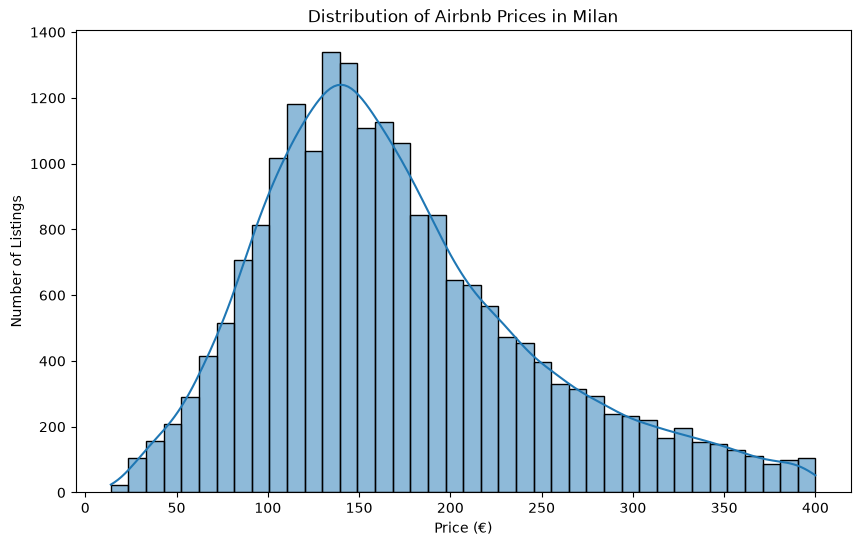

In [28]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_analysis,
    x='price',
    bins=40,
    kde=True
)

plt.title('Distribution of Airbnb Prices in Milan')
plt.xlabel('Price (€)')
plt.ylabel('Number of Listings')
plt.show()


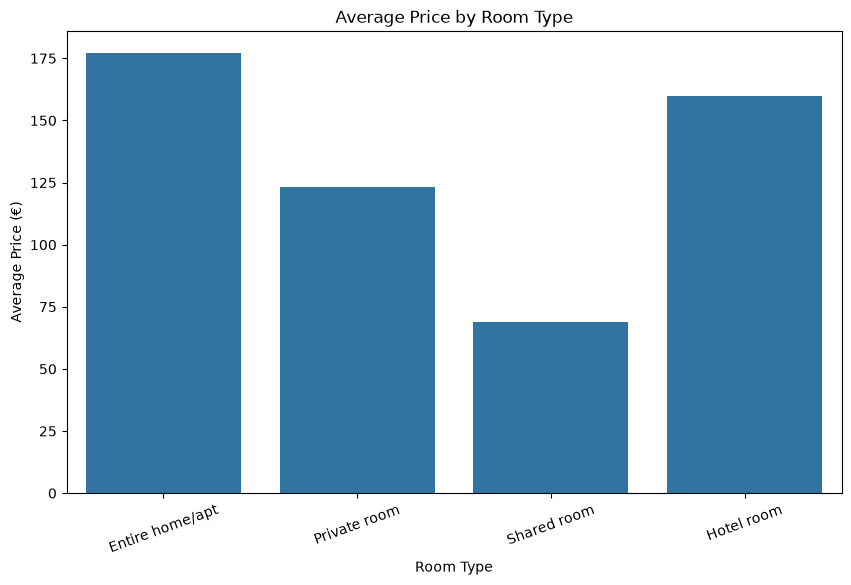

In [29]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df_analysis,
    x='room_type',
    y='price',
    estimator='mean',
    errorbar=None
)

plt.title('Average Price by Room Type')
plt.xlabel('Room Type')
plt.ylabel('Average Price (€)')
plt.xticks(rotation=20)
plt.show()


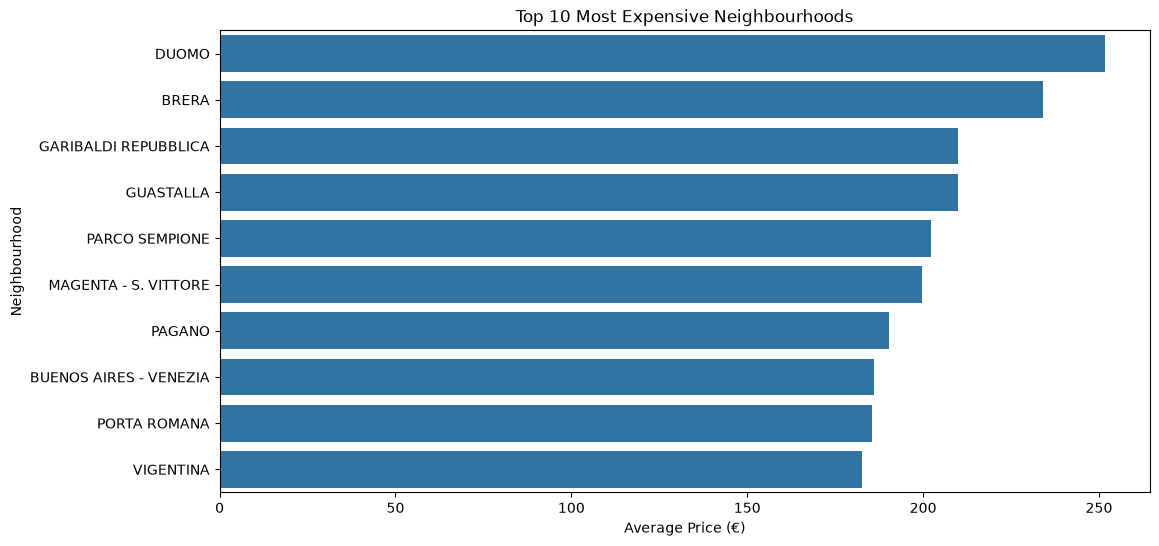

In [30]:

top_expensive = (
    df_analysis.groupby('neighbourhood')['price']
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_expensive,
    x='price',
    y='neighbourhood'
)

plt.title('Top 10 Most Expensive Neighbourhoods')
plt.xlabel('Average Price (€)')
plt.ylabel('Neighbourhood')
plt.show()


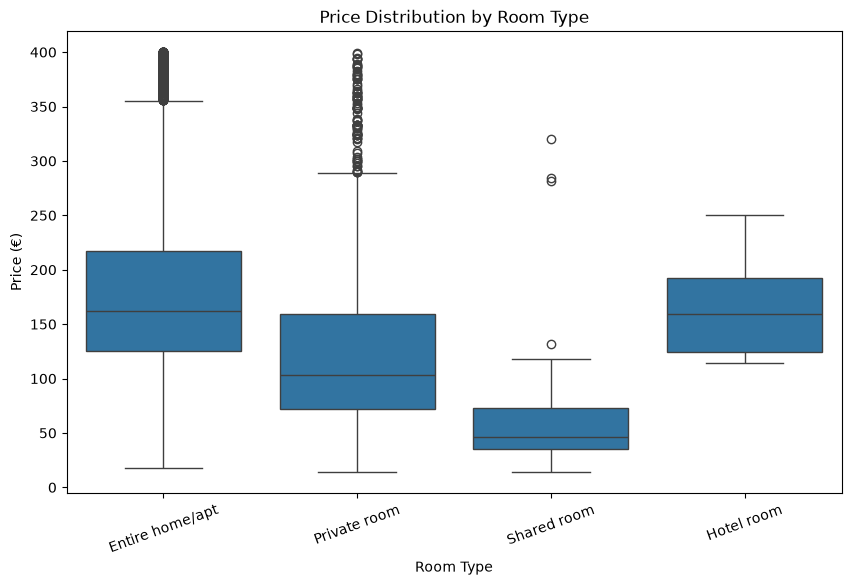

In [31]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_analysis,
    x='room_type',
    y='price'
)

plt.title('Price Distribution by Room Type')
plt.xlabel('Room Type')
plt.ylabel('Price (€)')
plt.xticks(rotation=20)
plt.show()


In [32]:

numeric_columns = [
    'price',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'availability_365',
    'calculated_host_listings_count'
]

correlation_data = df_analysis[numeric_columns]

correlation_matrix = correlation_data.corr()

print(correlation_matrix)


                                   price  minimum_nights  number_of_reviews  \
price                           1.000000       -0.261319          -0.066458   
minimum_nights                 -0.261319        1.000000          -0.129528   
number_of_reviews              -0.066458       -0.129528           1.000000   
reviews_per_month              -0.053477       -0.205655           0.564049   
availability_365                0.045187        0.156270          -0.054334   
calculated_host_listings_count  0.125158       -0.074443          -0.099625   

                                reviews_per_month  availability_365  \
price                                   -0.053477          0.045187   
minimum_nights                          -0.205655          0.156270   
number_of_reviews                        0.564049         -0.054334   
reviews_per_month                        1.000000         -0.029177   
availability_365                        -0.029177          1.000000   
calculated_host_list

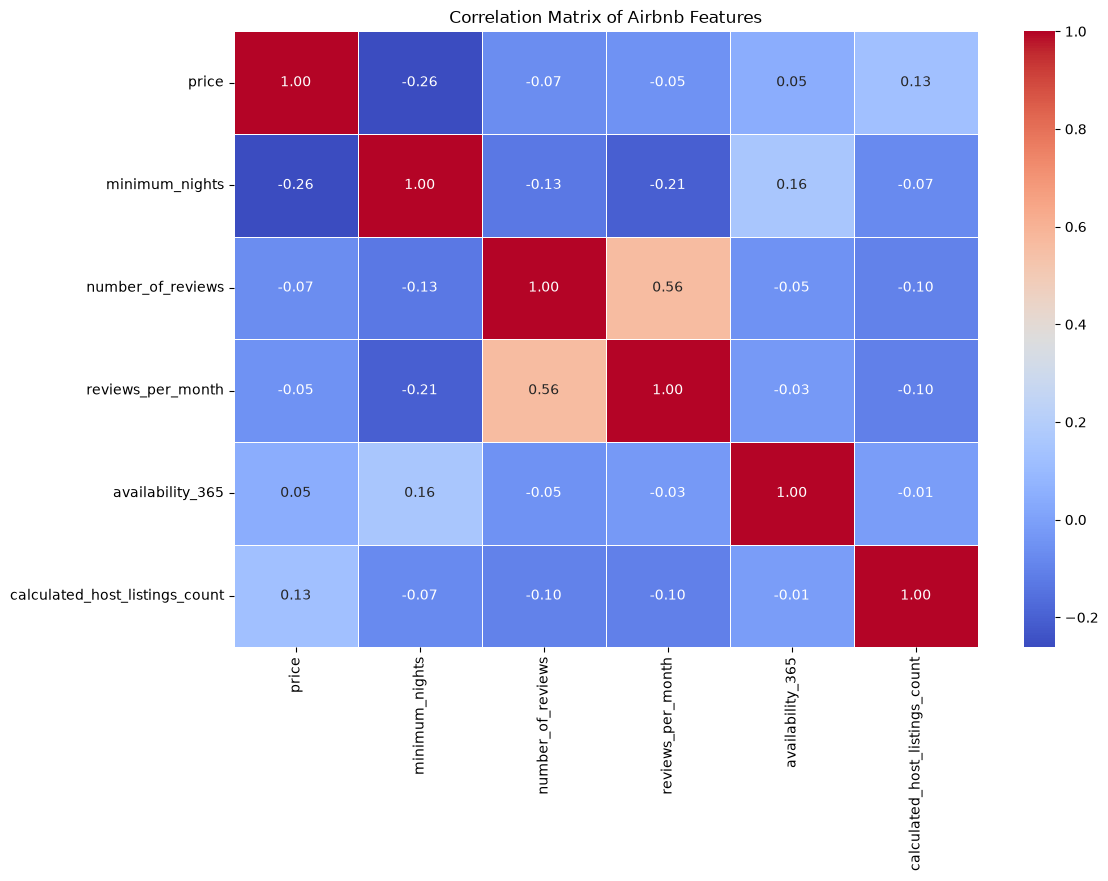

In [33]:

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix of Airbnb Features')
plt.show()


In [34]:

price_correlation = (
    correlation_matrix['price']
    .drop('price')
    .sort_values(ascending=False)
)

print("Correlation with Price:")
print(price_correlation)



Correlation with Price:
calculated_host_listings_count    0.125158
availability_365                  0.045187
reviews_per_month                -0.053477
number_of_reviews                -0.066458
minimum_nights                   -0.261319
Name: price, dtype: float64


In [39]:

numeric_columns = [
    'price',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'availability_365',
    'calculated_host_listings_count'
]

correlation_data = df_analysis[numeric_columns]

correlation_matrix = correlation_data.corr()

print(correlation_matrix)


                                   price  minimum_nights  number_of_reviews  \
price                           1.000000       -0.261319          -0.066458   
minimum_nights                 -0.261319        1.000000          -0.129528   
number_of_reviews              -0.066458       -0.129528           1.000000   
reviews_per_month              -0.053477       -0.205655           0.564049   
availability_365                0.045187        0.156270          -0.054334   
calculated_host_listings_count  0.125158       -0.074443          -0.099625   

                                reviews_per_month  availability_365  \
price                                   -0.053477          0.045187   
minimum_nights                          -0.205655          0.156270   
number_of_reviews                        0.564049         -0.054334   
reviews_per_month                        1.000000         -0.029177   
availability_365                        -0.029177          1.000000   
calculated_host_list

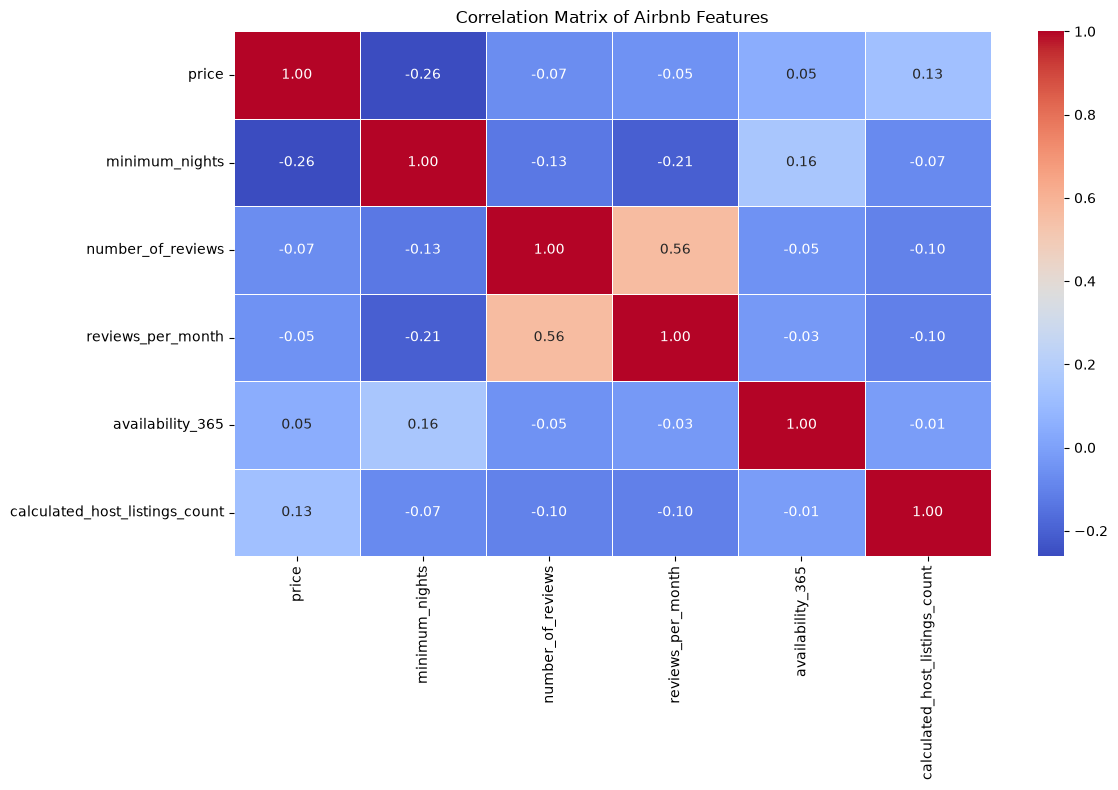

In [40]:

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix of Airbnb Features')
plt.tight_layout()
plt.show()



In [41]:

price_correlation = (
    correlation_matrix['price']
    .drop('price')
    .sort_values(ascending=False)
)

print("Correlation with Price:")
print(price_correlation)


Correlation with Price:
calculated_host_listings_count    0.125158
availability_365                  0.045187
reviews_per_month                -0.053477
number_of_reviews                -0.066458
minimum_nights                   -0.261319
Name: price, dtype: float64


In [42]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [43]:

# Select features for clustering

cluster_data = df_analysis[['price', 'minimum_nights']].copy()

# Remove missing values
cluster_data = cluster_data.dropna()

print(cluster_data.head())


   price  minimum_nights
0  203.0            31.0
1  137.0             3.0
4  102.0            31.0
6  105.0             1.0
7  102.0             1.0


In [44]:

scaler = StandardScaler()

scaled_data = scaler.fit_transform(cluster_data)


In [45]:

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_data['Cluster'] = kmeans.fit_predict(scaled_data)

print(cluster_data.head())


   price  minimum_nights  Cluster
0  203.0            31.0        2
1  137.0             3.0        0
4  102.0            31.0        2
6  105.0             1.0        0
7  102.0             1.0        0


In [46]:

cluster_summary = cluster_data.groupby('Cluster').agg(
    listings_count=('price', 'count'),
    average_price=('price', 'mean'),
    average_minimum_nights=('minimum_nights', 'mean')
)

print(cluster_summary)


         listings_count  average_price  average_minimum_nights
Cluster                                                       
0                 12611     141.265245                1.532630
1                  5150     273.410874                2.265437
2                  2195      97.810023               34.808200


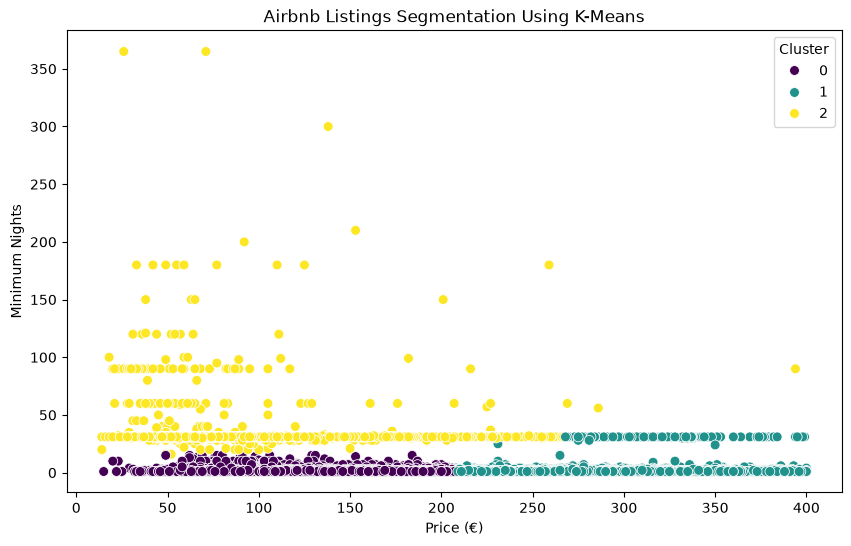

In [47]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=cluster_data,
    x='price',
    y='minimum_nights',
    hue='Cluster',
    palette='viridis',
    s=50
)

plt.title('Airbnb Listings Segmentation Using K-Means')
plt.xlabel('Price (€)')
plt.ylabel('Minimum Nights')
plt.legend(title='Cluster')
plt.show()
